# 52 — Thesis figures, Part III (Dominant design)

This notebook draws every figure and table of this part of the thesis and writes them, as PDF (for the thesis), PNG and CSV, to
`thesis_figures_v2/Part_III_dominant_design/<group>/<role>/`. Run it top to bottom; every cell shows exactly the file that was written.

| group | role | file | kind | what it shows |
|---|---|---|---|---|
| III1. Architecture shares | main | `q6_architecture_shares_by_cohort` | figure | Architecture share per priority cohort |
| III1. Architecture shares | main | `q6_largest_architectures_over_time` | figure | Five largest architectures over time |
| III1. Architecture shares | main | `q6_share_trend_spearman` | table | Spearman rho of each architecture's share on priority year |
| III2 and III3. Dominant design | main | `q7_condition1_family` | figure | Condition 1 on F per priority year |
| III2 and III3. Dominant design | main | `q7_condition2_balance` | figure | Condition 2: ²D against its band |
| III2 and III3. Dominant design | main | `q7_condition3_cohesion` | figure | Condition 3: ΔQ against its band |
| III2 and III3. Dominant design | main | `q7_family_conditions` | figure | The three conditions on F (III.3) |
| III2 and III3. Dominant design | appendix | `q7_verdict_table` | table | The dominant-design verdict, levels A, A·W·T, A·U and F |
| III2 and III3. Dominant design | appendix | `q7_condition3_weights` | table | Weights of the form distance |
| III2 and III3. Dominant design | appendix | `q7_three_year_check` | table | Condition 1 with three consecutive years |
| III2 and III3. Dominant design | appendix | `q7_granted_live_condition1` | table | F's share on granted and live patents alone |
| III2 and III3. Dominant design | appendix | `q7_granted_live_condition2` | table | ²D of F on granted and live patents alone |
| III4. The directory's five categories | main | `q7_iii4_directory_categories` | figure | Conditions 1 and 2 on the five directory categories |
| III4. The directory's five categories | appendix | `q7_iii4_directory_fold` | table | Architectures folded to the directory categories |

**Roles:** *main* goes in the chapter, *auxiliary* backs a statement of the chapter, *appendix* goes to the appendix.

## Where the numbers come from

- **The patent dataset** (627 designs): the author's characterisation of the patent drawings, read through `viz/thesis_q6.py`, `thesis_q7.py` and `viz/analysis3.py`. This notebook only draws.
- **Legal status** (PatSeer, snapshot 2026-06-08): *actively protected* = at least one linked patent in force; *granted and live* = at least one granted patent in force.
- **Directory categories**: `analysis.class_fold` of `labelling_analysis.yaml` (SLC, SRW → LC; TR, TW, CVT, TB, PTC, DS → VT; MR → WM; RC → ER; HB, PFV → HB), the fold of the evtol.news comparison; Table architectureFold of Appendix D was not available to check against.
- **Permutations**: 200, seed 42; ²D rarefied to 40 designs. Disparity is not rerun for III4.
- **Terms used in the figures:** architecture, design, cohort (a window of priority years), assignee; levels of description A = architecture alone, A·W·T = architecture, number of wings and whether any propulsor tilts, A·U = architecture and propulsor-unit band; F = Lift + Cruise + CVT* family.

## Look and layout rules

Every figure is drawn under the author's thesis style, `viz/part1.mplstyle` (style 1, chosen 2026-10-12 among five in `viz/style_options/`):
Arial-type sans (Liberation Sans here), 9 pt labels, 8 pt ticks and legends, no top or right frame, a light horizontal grid, 6.3 in wide, PDF with embedded fonts.

The rules each figure is held to, and checked against in this notebook (`viz/figcheck.py`):

1. **No text on top of other text or of a mark.** Checked automatically: the check table at the end must read 0.
2. **Anything in columns is placed at fixed positions, never padded with spaces** (for example a numbered key), so rows line up exactly.
3. **One grid per plot**: a right-hand second axis draws no grid of its own.
4. **Words, not codes**: every abbreviation in a figure is spelled out in the figure or its key.
5. **No title inside the figure**: the caption in the thesis carries it.
6. **Nothing under 6.5 pt** at print size. Checked automatically.

## Setup

In [1]:
import sys, pathlib, importlib
PILLAR = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(PILLAR))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from viz import config, thesis, figcheck
v2 = importlib.import_module('viz.thesis_v2_part3')
cfg = config.load()
ctx = thesis.context(cfg)
OUT = v2.out_root(cfg)
print(len(ctx.v), 'designs | external inputs:', cfg.analysis.get('external_inputs', 'script'), '| writing to', OUT)
CHECKS = []
FORBIDDEN = ()

def show(name):
    """Build the item once under the thesis style, write it, check its layout, and show the written file."""
    it = next(i for i in v2.ITEMS if i['name'] == name)
    obj, data = v2.save_v2_item(it, cfg, ctx)
    folder = OUT / it['group'] / it['role']
    if it['kind'] == 'figure':
        final = bool(it.get('width'))
        rep = figcheck.final_figure_report(obj, width_in=it['width'] * v2.TEXT_W_IN if final else None,
                                           forbid=FORBIDDEN, floor_pt=7.0 if final else 6.5)
        ov = figcheck.overlaps(obj)
        row = {'file': name, 'group': it['group'], 'role': it['role'], 'final size': final, **rep,
                'problems': '; '.join(f'{a} | {b}' for a, b in ov[:3])}
        CHECKS.append(row)
        plt.close('all')
        display(Image(filename=str(folder / f'{name}.png'), width=760))
        bad = {k: v for k, v in rep.items() if (isinstance(v, bool) and not v) or (not isinstance(v, (bool, float)) and v not in (0,))}
        print(('layout OK' if not bad else f'CHECK: {bad} {ov[:3]}'), '|', folder / f'{name}.pdf')
    else:
        CHECKS.append({'file': name, 'group': it['group'], 'role': it['role'], 'final size': False, 'problems': 'table'})
        display(obj)
        print(folder / f'{name}.csv')

627 designs | external inputs: script | writing to /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_III_dominant_design


/home/vasco/Vasco Workspace/Tese_Vasco_Lnx/eVTOL-Visual-Evaluation/labeling_evaluation/viz/frames.py:560: UserWarning: rapidfuzz not installed — fuzzy company matching disabled. Only exact lookup table matches will be applied.
  canon = g._normalise_company(sraw)


## III1. Architecture shares

*How does each architecture's share of the designs move across cohorts, and which trends are monotonic?*

### Architecture share per priority cohort

`q6_architecture_shares_by_cohort` · main · figure · from v2 of q6_class_shares_by_window (Figure 10 (i))

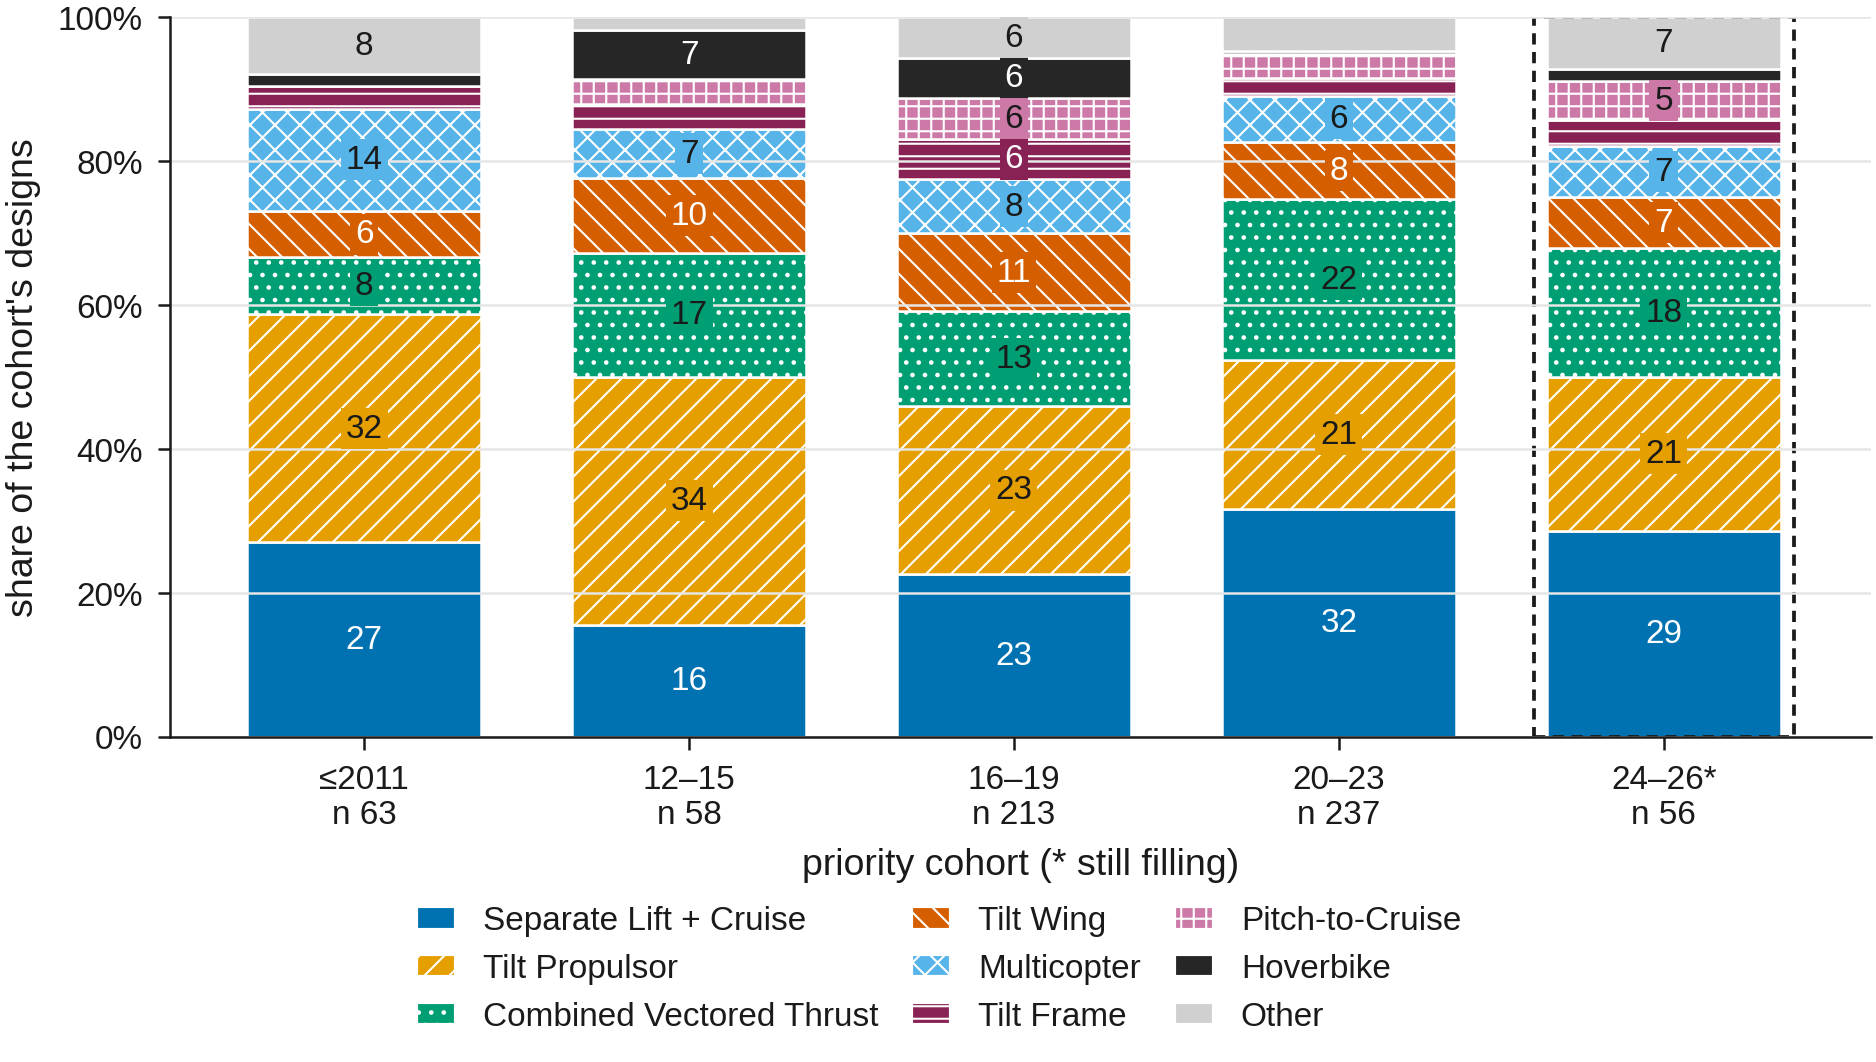

layout OK | /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_III_dominant_design/III1_architecture_shares/main/q6_architecture_shares_by_cohort.pdf


In [2]:
show('q6_architecture_shares_by_cohort')

### Five largest architectures over time

`q6_largest_architectures_over_time` · main · figure · from v2 of q6_largest_classes_over_time (Figure 10 (ii))

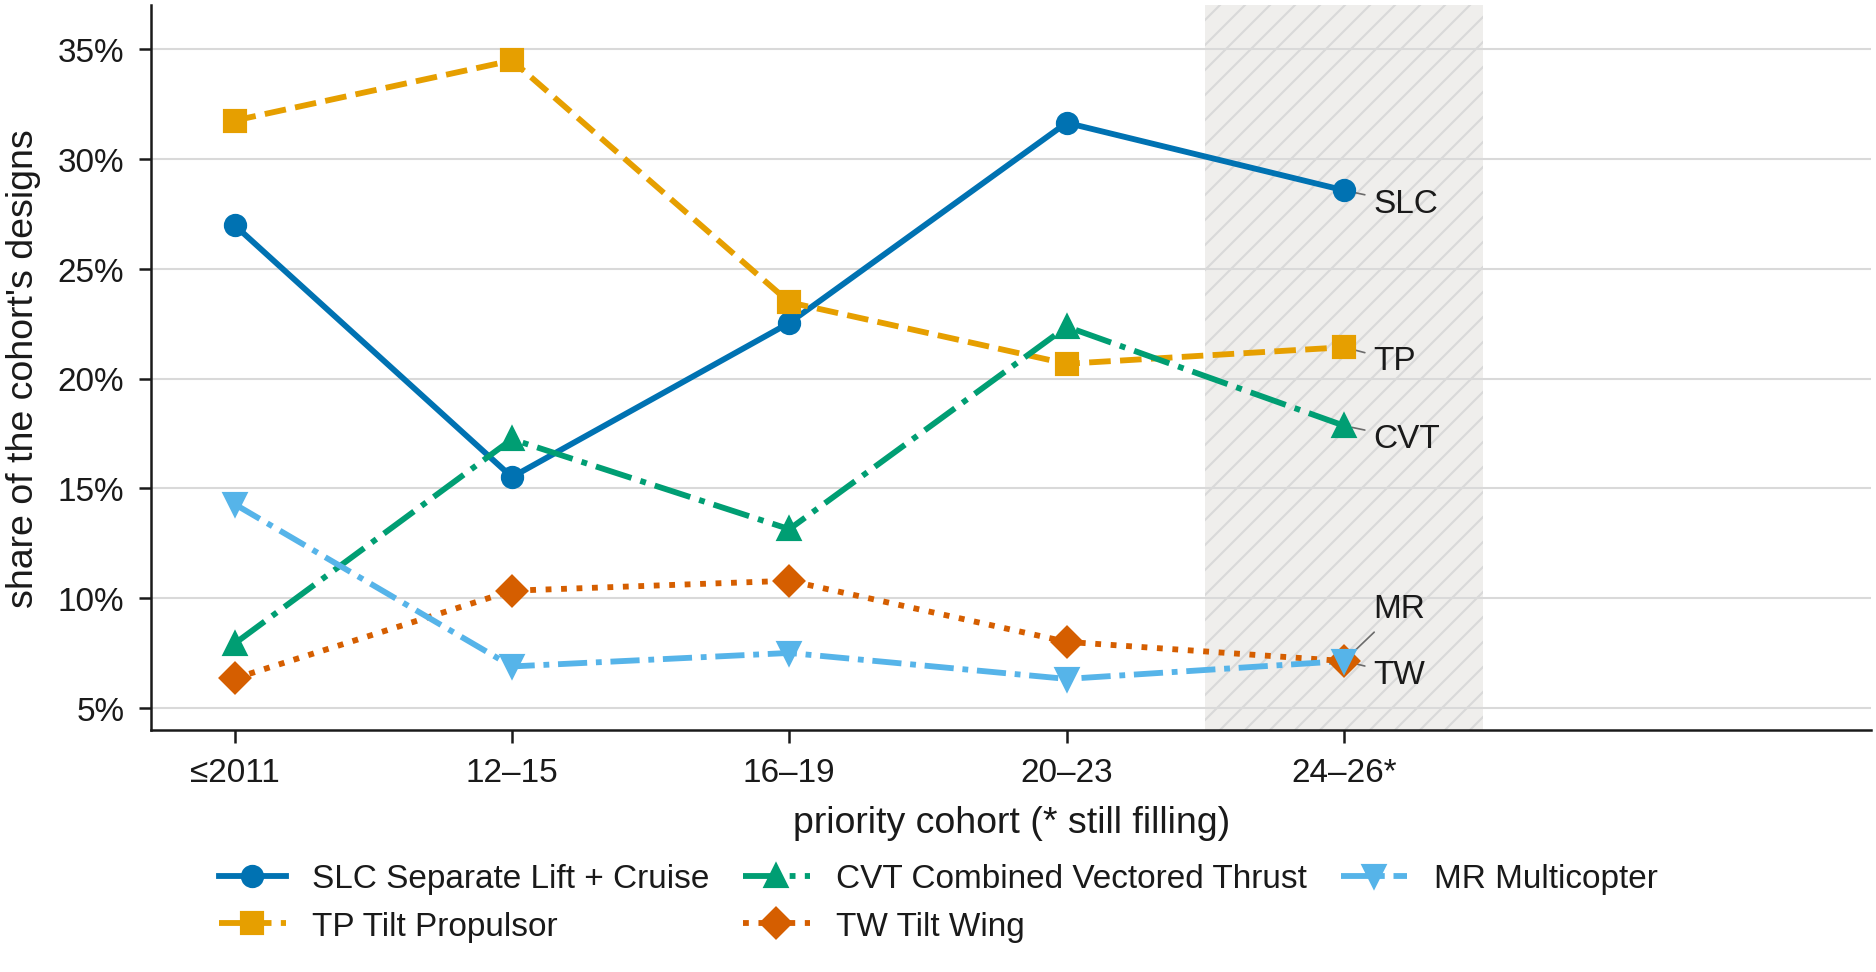

layout OK | /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_III_dominant_design/III1_architecture_shares/main/q6_largest_architectures_over_time.pdf


In [3]:
show('q6_largest_architectures_over_time')

### Spearman rho of each architecture's share on priority year

`q6_share_trend_spearman` · main · table · from new (Analysis III item 1)

In [4]:
show('q6_share_trend_spearman')

,architecture code,architecture,designs,years,rho,p,"rho, 2016-23","p, 2016-23"
0,SLC,Lift + Cruise,142,16,0.443,0.09,0.515,0.19
1,TP,Tilt Propulsor,132,16,-0.675,0.004,-0.357,0.39
2,CVT,Combined Vectored Thrust,93,16,0.255,0.34,0.548,0.16
3,TW,Tilt Wing,51,16,-0.169,0.53,-0.548,0.16
4,MR,Multicopter,37,16,0.074,0.78,-0.476,0.23
5,PTC,Pitch-to-Cruise,22,16,0.472,0.07,0.204,0.63
6,TF,Tilt Frame,22,16,-0.003,0.99,-0.286,0.49


/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_III_dominant_design/III1_architecture_shares/main/q6_share_trend_spearman.csv


## III2 and III3. Dominant design

*Does one level of description, A (architecture), A·W·T, A·U or the family F, meet the three conditions: share above half, balance below the band, form below the band?*

### Condition 1 on F per priority year

`q7_condition1_family` · main · figure · from v2 of q7_condition1_family (Figure 11)

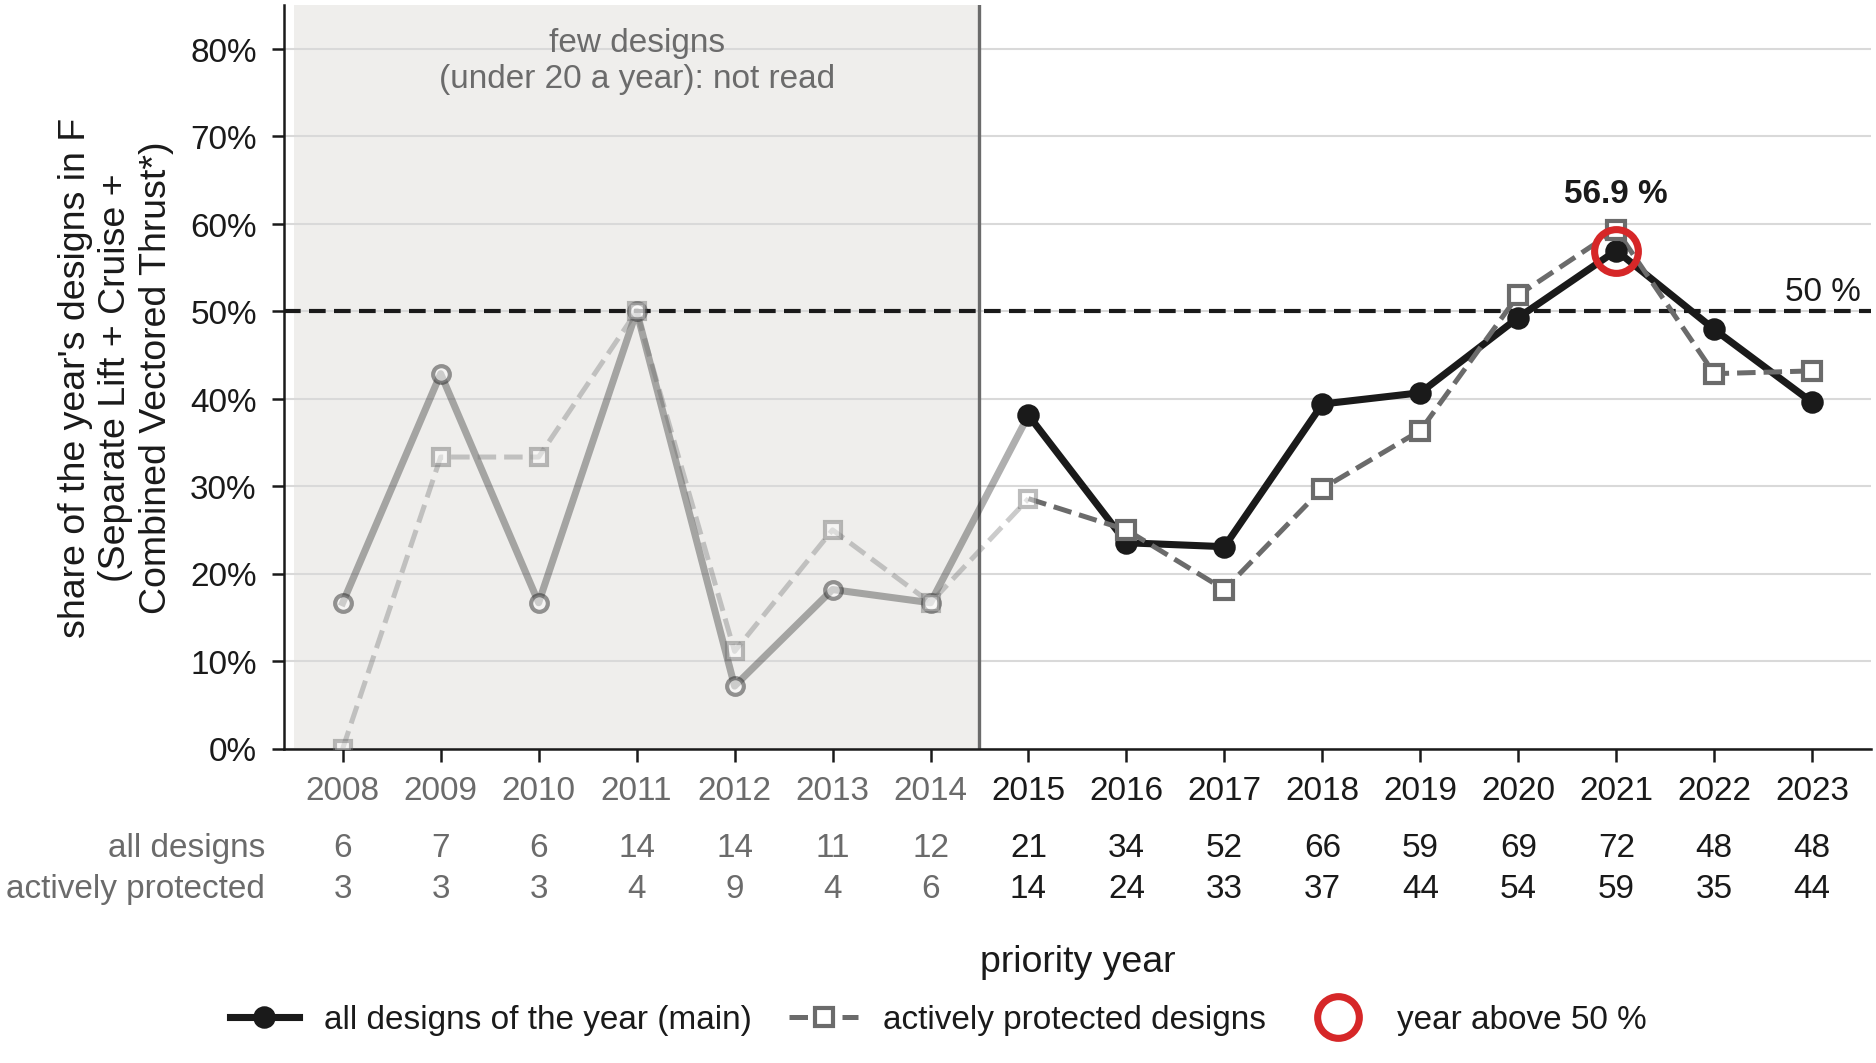

layout OK | /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_III_dominant_design/III2_III3_dominant_design/main/q7_condition1_family.pdf


In [5]:
show('q7_condition1_family')

### Condition 2: ²D against its band

`q7_condition2_balance` · main · figure · from v2 of q7_condition2_balance (Figure 12 (i))

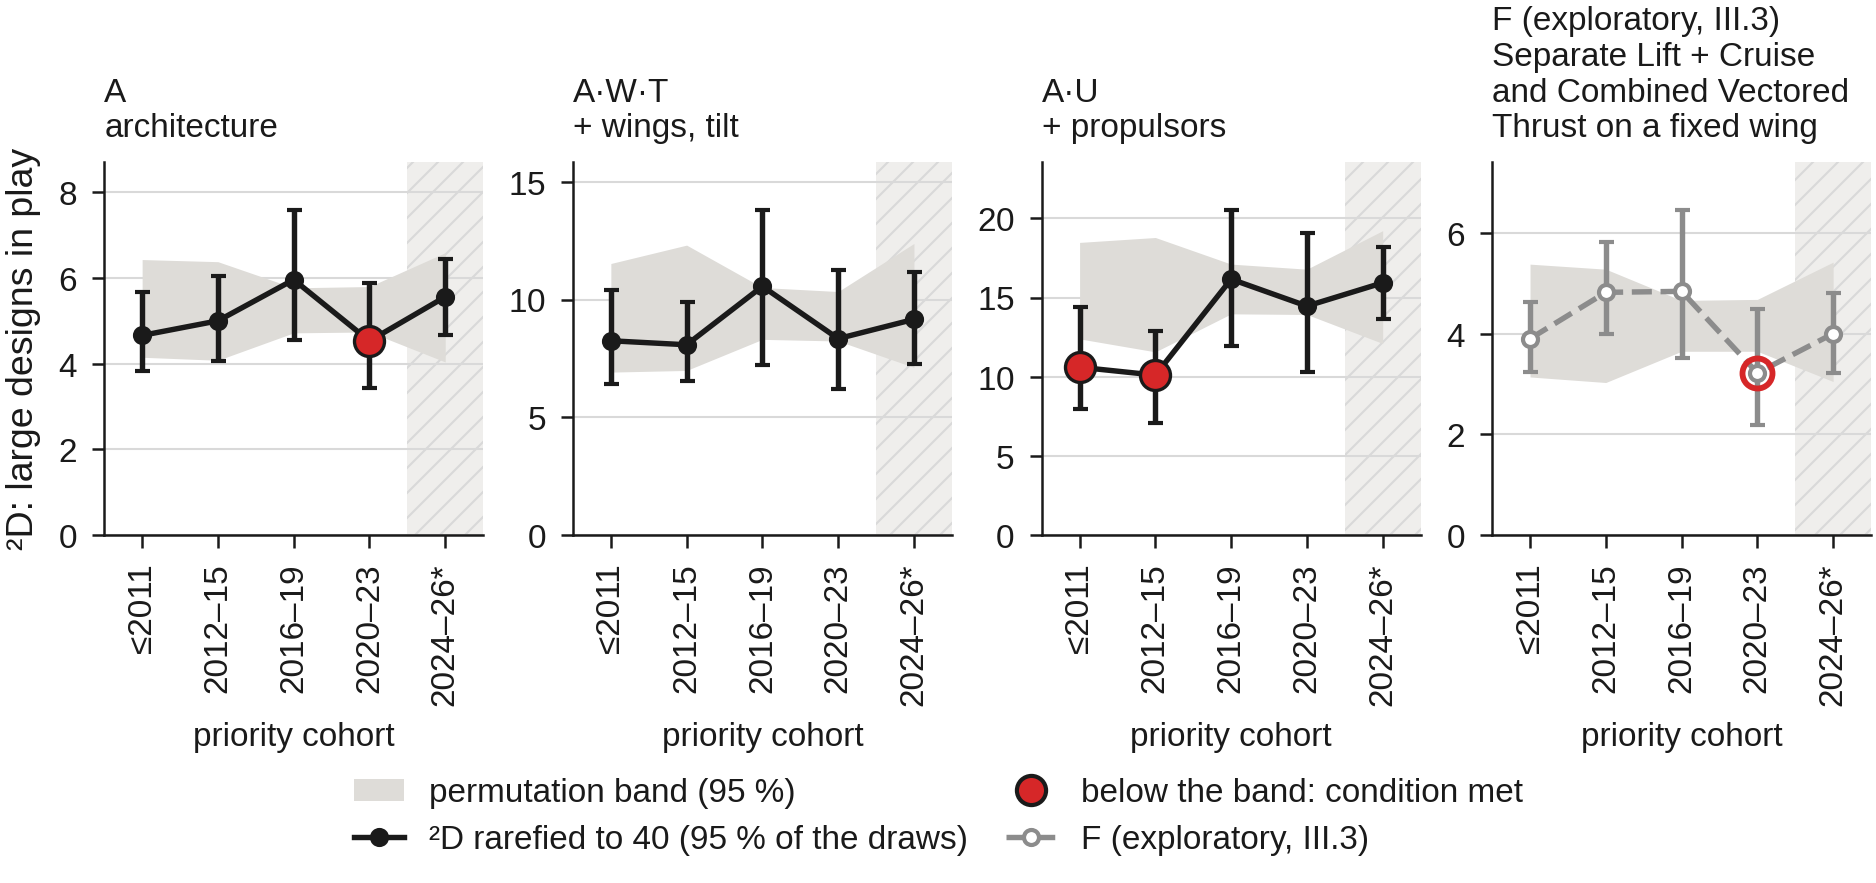

layout OK | /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_III_dominant_design/III2_III3_dominant_design/main/q7_condition2_balance.pdf


In [6]:
show('q7_condition2_balance')

### Condition 3: ΔQ against its band

`q7_condition3_cohesion` · main · figure · from v2 of q7_condition3_cohesion (Figure 12 (ii))

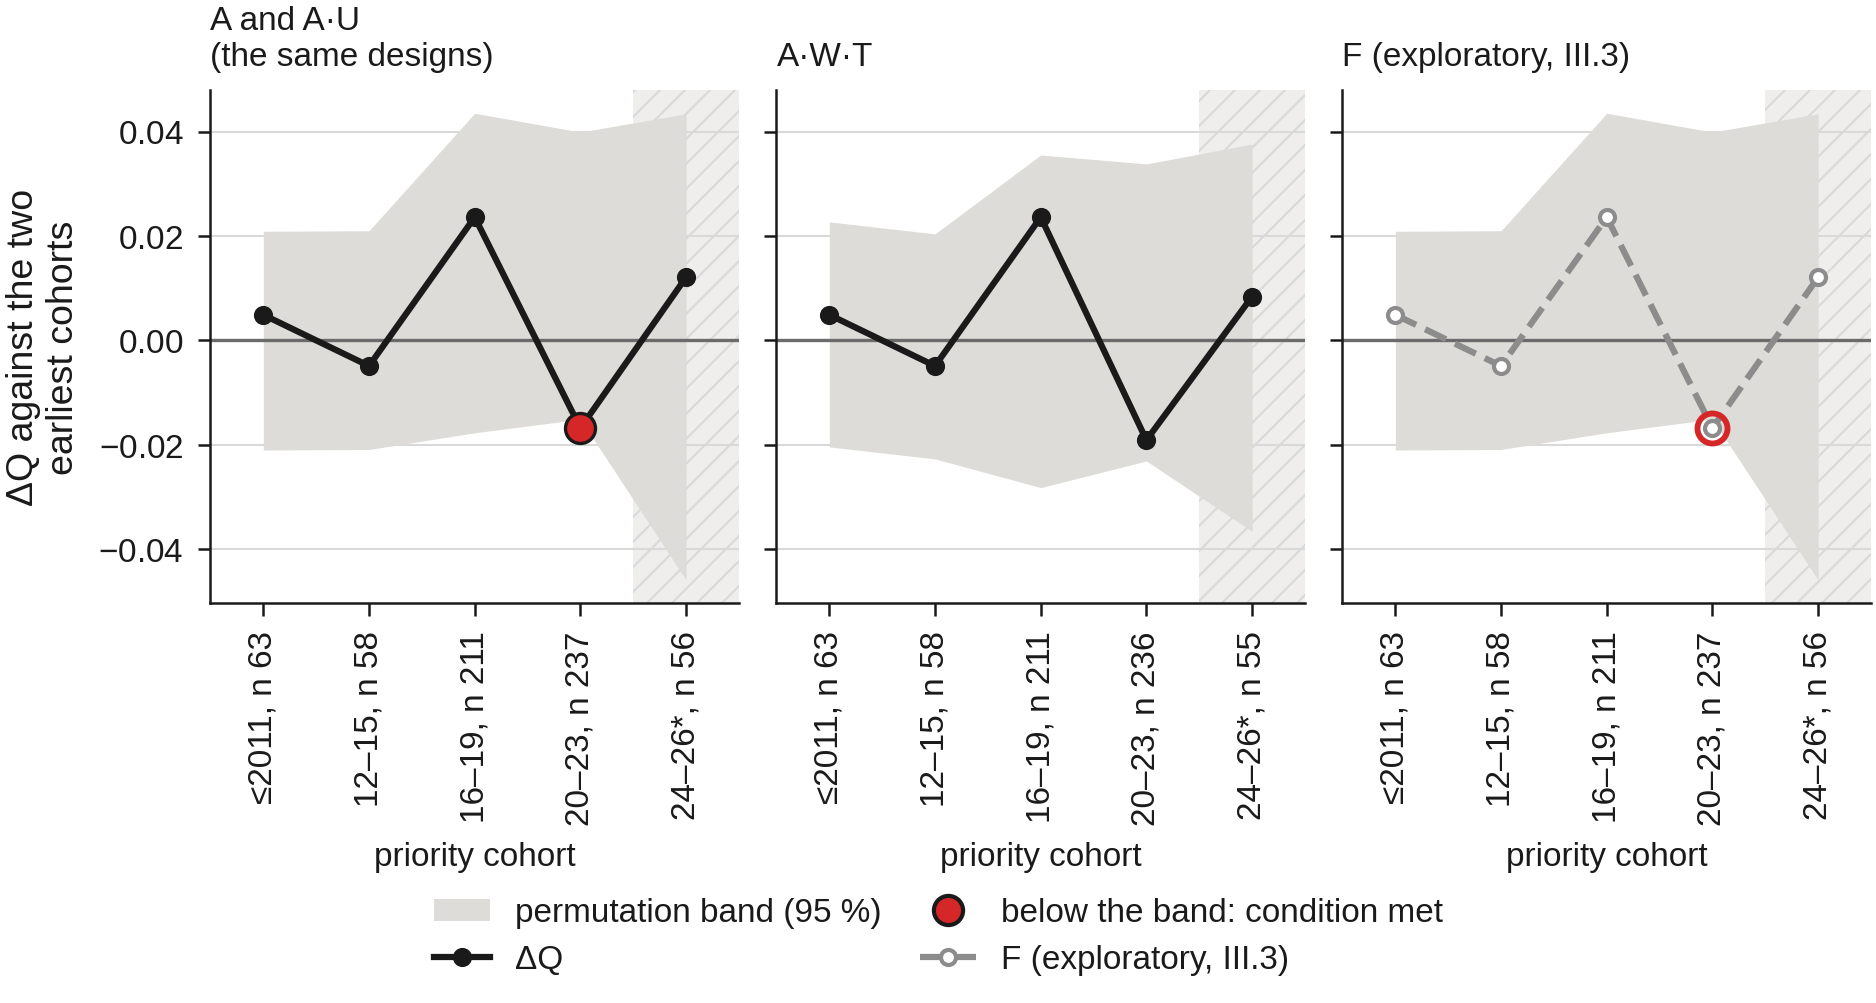

layout OK | /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_III_dominant_design/III2_III3_dominant_design/main/q7_condition3_cohesion.pdf


In [7]:
show('q7_condition3_cohesion')

### The three conditions on F (III.3)

`q7_family_conditions` · main · figure · new (hand-over 2026-10-16, Task 3): condition 1 (share per priority year, three bases), 2 (²D) and 3 (ΔQ) of F, all designs with the band and the actively protected series in grey.

In [ ]:
show('q7_family_conditions')

### The dominant-design verdict, levels A, A·W·T, A·U and F

`q7_verdict_table` · appendix · table · from v2 of q7_verdict_table (Table 8)

In [8]:
show('q7_verdict_table')

,base,condition,A,A·W·T,A·U,F
0,all designs,"1, counts: one architecture above 50 % of the ...","✗ not met, at most 36.2 % (2020)","✗ not met, at most 27.3 % (2018)","✗ not met, at most 19.4 % (2021)","✗ not met, at most 56.9 % (2021)"
1,all designs,"2, balance: ²D below the permutation band",✓ met in 2020-23,✗ not met,"✓ met in <= 2011, 2012-15",✓ met in 2020-23
2,all designs,"3, form: Q below the two earliest cohorts by m...",✓ met in 2020-23,✗ not met,✓ met in 2020-23,✓ met in 2020-23
3,all designs,all three in the same period,✗ not met,✗ not met,✗ not met,✗ not met
4,actively protected,"1, counts: one architecture above 50 % of the ...","✗ not met, at most 39.0 % (2021)","✗ not met, at most 27.1 % (2021)","✗ not met, at most 23.7 % (2021)","✓ met in 2020 and 2021 (51.8 %, 59.3 %)"
5,actively protected,"2, balance: ²D below the permutation band",✓ met in 2020-23,"✓ met in <= 2011, 2020-23","✓ met in <= 2011, 2012-15, 2020-23",✓ met in 2020-23
6,actively protected,"3, form: Q below the two earliest cohorts by m...",✗ not met,✗ not met,✗ not met,✗ not met
7,actively protected,all three in the same period,✗ not met,✗ not met,✗ not met,✗ not met


/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_III_dominant_design/III2_III3_dominant_design/appendix/q7_verdict_table.csv


In [9]:
show('q7_verdict_detail')

,base,level,condition 1: largest share,condition 1: its year,condition 1: years met,condition 1: share 2020 (n of N),condition 1: share 2021 (n of N),²D <= 2011,²D lower band edge <= 2011,²D 2012-15,²D lower band edge 2012-15,²D 2016-19,²D lower band edge 2016-19,²D 2020-23,²D lower band edge 2020-23,ΔQ 2020-23,ΔQ lower band edge 2020-23
0,all designs,A,36.2 %,2020,none,36.2 % (25 of 69),33.3 % (24 of 72),4.66,4.15,5.00,4.08,5.96,4.72,4.53,4.74,-0.0168,-0.0151
1,all designs,A·W·T,27.3 %,2018,none,24.6 % (17 of 69),23.6 % (17 of 72),8.25,6.92,8.08,6.99,10.56,8.31,8.34,8.24,-0.0191,-0.0231
2,all designs,A·U,19.4 %,2021,none,14.5 % (10 of 69),19.4 % (14 of 72),10.60,12.39,10.10,11.57,16.16,13.97,14.46,13.93,-0.0191,-0.0163
3,all designs,F,56.9 %,2021,none,49.3 % (34 of 69),56.9 % (41 of 72),3.90,3.14,4.82,3.03,4.84,3.65,3.22,3.65,-0.0168,-0.0151
4,actively protected,A,39.0 %,2021,none,38.9 % (21 of 54),39.0 % (23 of 59),3.00,2.89,4.02,3.69,6.04,4.49,4.43,4.69,0.0368,-0.0176
5,actively protected,A·W·T,27.1 %,2021,none,24.1 % (13 of 54),27.1 % (16 of 59),4.15,4.91,6.68,6.08,11.31,8.13,8.33,8.43,0.0338,-0.0214
6,actively protected,A·U,23.7 %,2021,none,16.7 % (9 of 54),23.7 % (14 of 59),5.59,7.04,7.72,10.37,16.32,13.57,13.82,13.97,0.0338,-0.0223
7,actively protected,F,59.3 %,2021,"2020, 2021",51.8 % (28 of 54),59.3 % (35 of 59),2.84,2.42,3.93,2.73,5.17,3.30,3.14,3.58,0.0368,-0.0176


/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_III_dominant_design/III2_III3_dominant_design/appendix/q7_verdict_detail.csv


In [10]:
show('q7_condition3_family')

,base,cohort,designs,Q,Q of the earliest cohorts,ΔQ,ΔQ permutation low,ΔQ permutation high,below band,partial
0,actively protected,<= 2011,18,0.4944,0.5161,-0.0216,-0.0449,0.0395,False,False
1,actively protected,2012-15,33,0.5377,0.5161,0.0216,-0.0395,0.0449,False,False
2,actively protected,2016-19,138,0.5984,0.5161,0.0824,-0.0277,0.0632,False,False
3,actively protected,2020-23,192,0.5528,0.5161,0.0368,-0.0176,0.0697,False,False
4,actively protected,2024-26 (partial),52,0.5752,0.5161,0.0591,-0.0414,0.0690,False,True
5,all designs,<= 2011,63,0.5772,0.5723,0.0049,-0.0210,0.0209,False,False
6,all designs,2012-15,58,0.5675,0.5723,-0.0049,-0.0209,0.0210,False,False
7,all designs,2016-19,211,0.5960,0.5723,0.0236,-0.0177,0.0435,False,False
8,all designs,2020-23,237,0.5555,0.5723,-0.0168,-0.0151,0.0399,True,False
9,all designs,2024-26 (partial),56,0.5844,0.5723,0.0121,-0.0459,0.0434,False,True


/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_III_dominant_design/III2_III3_dominant_design/appendix/q7_condition3_family.csv


### Weights of the form distance

`q7_condition3_weights` · appendix · table · from new (Analysis III item 2)

In [11]:
show('q7_condition3_weights')

,system,dimensions,count,weight of each,weight in all
0,G1 architecture,Architecture,1,1.000,1.000
1,M1 structure,Fuselage Shape; Fuselage Kinematics; Ground Co...,14,0.071,1.000
2,M2 wings,Wing Architecture; Wing count; Vertical Positi...,8,0.083,0.667
3,M2 empennage,Empennage Type,1,0.333,0.333
4,M3 propulsion,Propulsor count; Thrust Kinematics; Propulsor ...,10,0.100,1.000
5,total,,34,NaN,4.000


/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_III_dominant_design/III2_III3_dominant_design/appendix/q7_condition3_weights.csv


### Condition 1 with three consecutive years

`q7_three_year_check` · appendix · table · from new (Analysis III item 4)

In [12]:
show('q7_three_year_check')

,level,"years above 50 % in three consecutive years, actively protected designs"
0,A,none
1,A·W·T,none
2,A·U,none
3,F,none


/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_III_dominant_design/III2_III3_dominant_design/appendix/q7_three_year_check.csv


### F's share on granted and live patents alone

`q7_granted_live_condition1` · appendix · table · from new (Analysis III item 5)

In [13]:
show('q7_granted_live_condition1')

,priority year,designs,F designs,share of F,read (20 designs or more)
8,2016,24,6,0.2500,True
9,2017,32,5,0.1562,True
10,2018,35,11,0.3143,True
11,2019,44,16,0.3636,True
12,2020,51,27,0.5294,True
13,2021,54,32,0.5926,True
14,2022,28,11,0.3929,True
15,2023,15,9,0.6000,False


/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_III_dominant_design/III2_III3_dominant_design/appendix/q7_granted_live_condition1.csv


### ²D of F on granted and live patents alone

`q7_granted_live_condition2` · appendix · table · from new (Analysis III item 5)

In [14]:
show('q7_granted_live_condition2')

,cohort,designs,²D,"band, lower edge","band, upper edge",below band
0,<= 2011,18,2.84,2.31,5.60,False
1,2012-15,32,4.10,2.67,5.69,False
2,2016-19,135,5.14,3.54,4.56,False
3,2020-23,148,3.03,3.55,4.64,True
4,2024-26 (partial),10,3.33,1.92,5.56,False


/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_III_dominant_design/III2_III3_dominant_design/appendix/q7_granted_live_condition2.csv


## III4. The directory's five categories

*Do the conditions hold when the twelve architectures are folded to the five categories of the public directory?*

### Conditions 1 and 2 on the five directory categories

`q7_iii4_directory_categories` · main · figure · from new (Analysis III item 6)

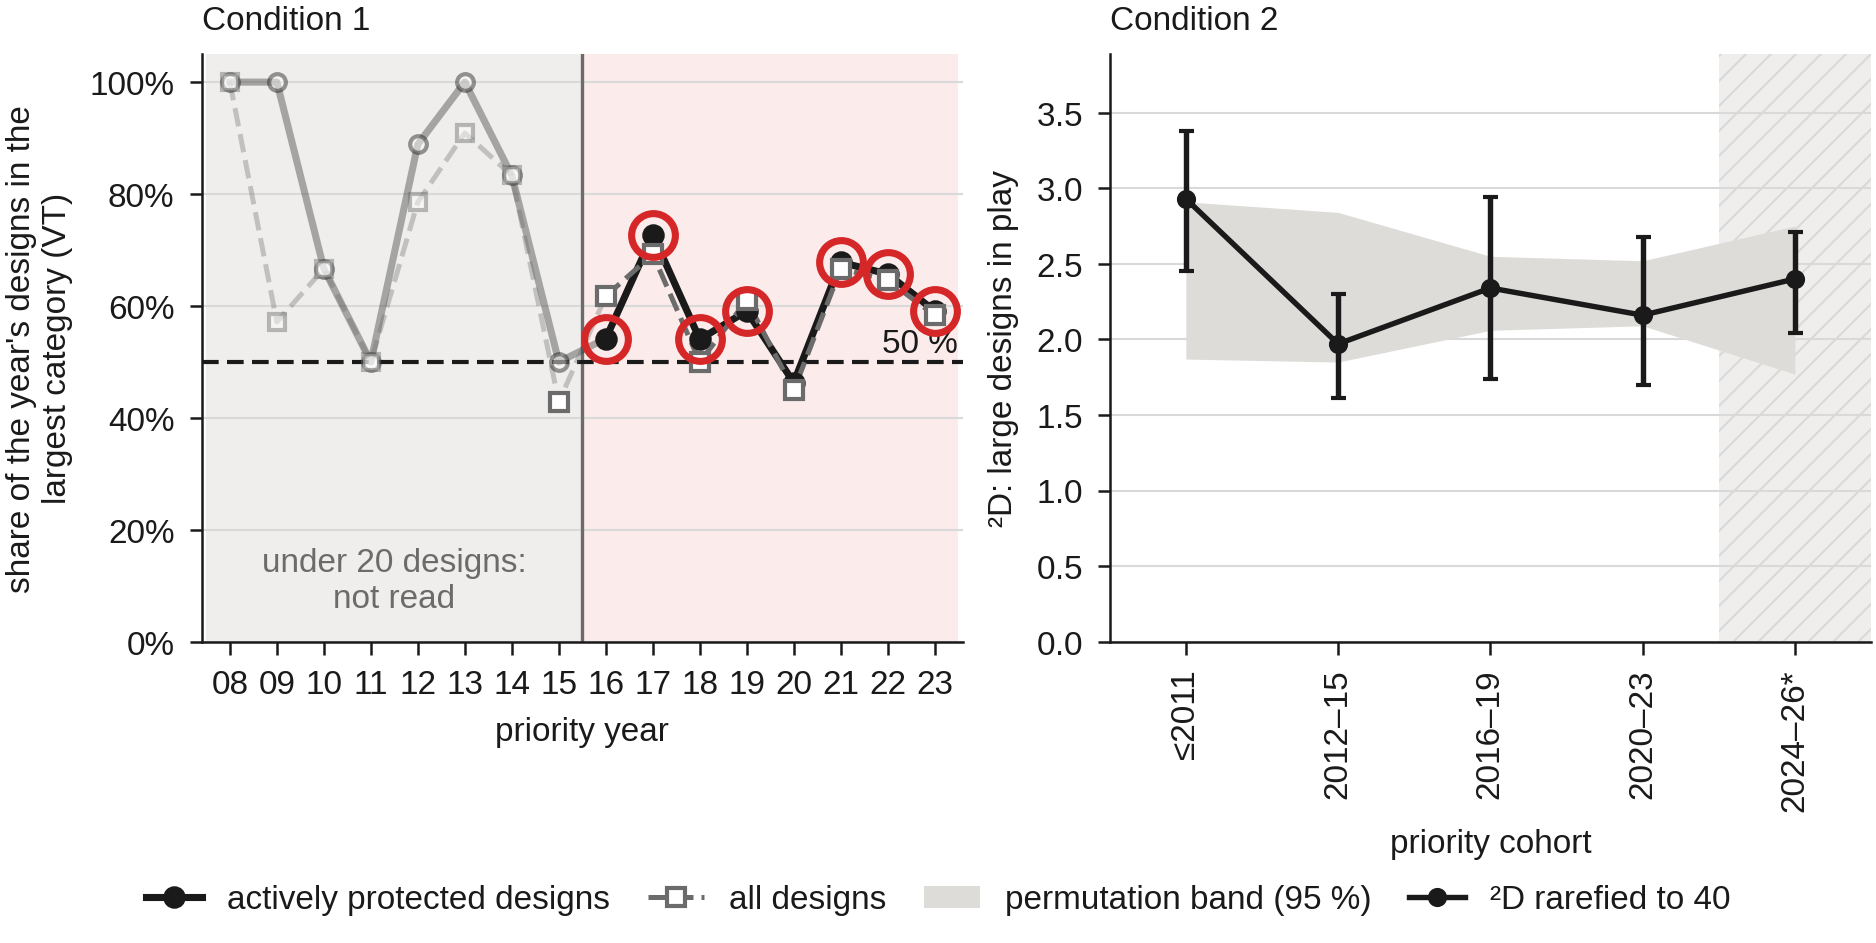

layout OK | /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_III_dominant_design/III4_directory_categories/main/q7_iii4_directory_categories.pdf


In [15]:
show('q7_iii4_directory_categories')

### Architectures folded to the directory categories

`q7_iii4_directory_fold` · appendix · table · from analysis.class_fold

In [16]:
show('q7_iii4_directory_fold')

,directory category,architecture code,architecture,designs
0,ER,RC,Rotorcraft,9
1,HB,HB,Hoverbike,19
2,HB,PFV,Personal Flying Vehicle,10
3,LC,SLC,Lift + Cruise,165
4,LC,SRW,Stopped/Slowed Rotor Wing,8
5,VT,CVT,Combined Vectored Thrust,106
6,VT,DS,Deflected Slipstream,4
7,VT,PTC,Pitch-to-Cruise,25
8,VT,TF,Tilt Frame,24
9,VT,TP,Tilt Propulsor,151


/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_III_dominant_design/III4_directory_categories/appendix/q7_iii4_directory_fold.csv


## Layout check, all figures

Every count must read 0 and every flag True: text over text, text under the font floor (7 pt for the figures printed in the dissertation, 6.5 pt for the others), text outside the canvas, forbidden words, the final width, and the height of at most 55 % of the width.

In [17]:
chk = pd.DataFrame(CHECKS)
display(chk)
figs = chk[chk['problems'] != 'table']
num = [c for c in figs.columns if c in ('text over text', 'under 7 pt', 'under 6 pt', 'outside canvas', 'forbidden words')]
flags = [c for c in ('width_ok', 'height_ok') if c in figs.columns]
ok = all((figs[c].fillna(0) == 0).all() for c in num) and all(figs[c].dropna().astype(bool).all() for c in flags)
print('all figures pass' if ok else 'SOME FIGURES NEED A FIX (see the table)')

,file,group,role,final size,text over text,under 6 pt,outside canvas,forbidden words,problems
0,q6_architecture_shares_by_cohort,III1_architecture_shares,main,False,0.0,0.0,0.0,0.0,
1,q6_largest_architectures_over_time,III1_architecture_shares,main,False,0.0,0.0,0.0,0.0,
2,q6_share_trend_spearman,III1_architecture_shares,main,False,NaN,NaN,NaN,NaN,table
3,q7_condition1_family,III2_III3_dominant_design,main,False,0.0,0.0,0.0,0.0,
4,q7_condition2_balance,III2_III3_dominant_design,main,False,0.0,0.0,0.0,0.0,
5,q7_condition3_cohesion,III2_III3_dominant_design,main,False,0.0,0.0,0.0,0.0,
6,q7_verdict_table,III2_III3_dominant_design,appendix,False,NaN,NaN,NaN,NaN,table
7,q7_verdict_detail,III2_III3_dominant_design,appendix,False,NaN,NaN,NaN,NaN,table
8,q7_condition3_family,III2_III3_dominant_design,appendix,False,NaN,NaN,NaN,NaN,table
9,q7_condition3_weights,III2_III3_dominant_design,appendix,False,NaN,NaN,NaN,NaN,table


all figures pass


## Hand-over to the dissertation (LaTeX_v15)

The four figures that stay in the text and the two that leave it, redrawn at their final width in the 16 cm text block (1.0, 0.9, 0.85, 1.0; height at most 55 % of the width), with the data behind every figure and table, `NUMBERS_III.md` and the manifest lines. Nothing is recomputed differently; the builders are those above.

In [18]:
from viz import thesis_latex_part3 as hand
chk = hand.export(cfg, ctx)
display(chk)
print('all pass' if (chk['text over text'] == 0).all() and (chk['under 7 pt'] == 0).all() and (chk['height / width'] <= 0.55).all() else 'FIX NEEDED')
print(hand.root(cfg))

,figure,width cm,height cm,height / width,text over text,under 7 pt
0,q6_architecture_shares_by_cohort,16.0,8.80,0.550,0,0
1,q7_condition2_balance,14.4,7.62,0.529,0,0
2,q7_condition3_cohesion,13.6,7.48,0.550,0,0
3,q7_condition1_family,16.0,8.80,0.550,0,0
4,q6_largest_architectures_over_time,16.0,8.38,0.524,0,0
5,q7_iii4_directory_categories,16.0,8.13,0.508,0,0


all pass
/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/LaTeX_v15


## README and file list

Rewrite the folder's README.md and list every file written.

In [19]:
import subprocess
print(subprocess.run([sys.executable, str(PILLAR / 'notebooks' / '_build' / 'write_readme_52.py')], capture_output=True, text=True).stdout)
files = sorted(p.relative_to(OUT) for p in OUT.rglob('*') if p.is_file())
print(len(files), 'files'); files

README written /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_III_dominant_design/README.md

43 files


[PosixPath('III1_architecture_shares/main/q6_architecture_shares_by_cohort.csv'),
 PosixPath('III1_architecture_shares/main/q6_architecture_shares_by_cohort.json'),
 PosixPath('III1_architecture_shares/main/q6_architecture_shares_by_cohort.pdf'),
 PosixPath('III1_architecture_shares/main/q6_architecture_shares_by_cohort.png'),
 PosixPath('III1_architecture_shares/main/q6_largest_architectures_over_time.csv'),
 PosixPath('III1_architecture_shares/main/q6_largest_architectures_over_time.json'),
 PosixPath('III1_architecture_shares/main/q6_largest_architectures_over_time.pdf'),
 PosixPath('III1_architecture_shares/main/q6_largest_architectures_over_time.png'),
 PosixPath('III1_architecture_shares/main/q6_share_trend_spearman.csv'),
 PosixPath('III1_architecture_shares/main/q6_share_trend_spearman.json'),
 PosixPath('III2_III3_dominant_design/appendix/q7_condition3_family.csv'),
 PosixPath('III2_III3_dominant_design/appendix/q7_condition3_family.json'),
 PosixPath('III2_III3_dominant_desig

## Hand-over 2026-10-16 (Tasks 1 and 3)

Task 1: condition 3 rerun under the 15-dimension weighting `w15` (`frames.FORM15`, `frames.form_distance`; `w34` kept in the code for the record; same seed 42, 200 permutations, rarefaction and bases). The cells above wrote `q7_condition3_cohesion`, `q7_condition3_family`, `q7_condition3_weights`, `q7_verdict_table`, `q7_verdict_detail` and `NUMBERS_III.md`.
Task 3: F out of `q7_condition2_balance` and `q7_condition3_cohesion` (three panels A, A·W·T, A·U) and into the new `q7_family_conditions`; `q7_condition1_family` stays written but leaves the text.

This cell writes the other copies the hand-over asks for: png, csv and json beside the LaTeX_v15 pdfs (drawn at the final width), the notebook-size (v2) copies under `LaTeX_v15/Figures/thesis_figures_v2/...`, the Q7 items through the builder and writer of notebook 46 (`thesis_figures/Q7_dominant_design/results/`), and every file plus the changed scripts in `handoff_2026-10-16/` at the repository root.

In [ ]:
from viz import handoff_2026_10_16 as ho, thesis_latex_part3 as hand, thesis_q7 as q7
R = hand.root(cfg)
PART = 'Part_III_dominant_design'
written = []
TASK_FIGS = {'task1': ['q7_condition3_cohesion'], 'task3': ['q7_condition2_balance', 'q7_condition3_cohesion', 'q7_family_conditions']}
TASK_TABLES = {'task1': ['q7_condition3_family', 'q7_condition3_weights', 'q7_verdict_table', 'q7_verdict_detail']}
for task, names in TASK_FIGS.items():
    for name in names:
        it = next(i for i in v2.ITEMS if i['name'] == name)
        written += ho.figure_copies(task, name, it, PART, OUT / it['group'] / it['role'], R, lambda it=it, name=name: hand.draw(it, ctx, hand.FIGS[name][0])[:2])
        written += ho.q_item_copies(task, name, q7.ITEMS, ctx, cfg, suffix='q7results')
for task, names in TASK_TABLES.items():
    for name in names:
        it = next(i for i in v2.ITEMS if i['name'] == name)
        written += ho.table_copies(task, name, it, PART, OUT / it['group'] / it['role'], R)
written += ho.plain_copies('task1', [R / 'Data_for_writing' / 'NUMBERS_III.md'])
ho.copy_scripts('task1', ['lib/distance.py', 'viz/frames.py', 'viz/analysis3.py', 'viz/thesis_q7.py', 'viz/thesis_text_q7.py', 'viz/thesis_latex_part3.py',
                          'viz/thesis_v2_part3.py', 'viz/handoff_2026_10_16.py', 'notebooks/52_thesis_figures_v2_part3.ipynb'])
ho.copy_scripts('task3', ['viz/thesis_q7.py', 'viz/plots.py', 'viz/thesis_v2_part3.py', 'viz/thesis_latex_part3.py', 'viz/handoff_2026_10_16.py',
                          'notebooks/52_thesis_figures_v2_part3.ipynb'])
print('\n'.join(map(str, written)))
print(ho.listing('task1') + ho.listing('task3'))